In [1]:
source(file = "..//Libraries.R") |> suppressWarnings() |>  suppressMessages() 

In [16]:
data_mortality <- read.csv("..//data//owid_child_mortality.csv")
data_poverty <- read.csv("..//data//owid_poverty_lines.csv")
data_pip <- read.csv("..//data//worldbank_pip.csv")

In [3]:
head(data_poverty)
head(data_mortality)

,Country,Year,Share.below..1.a.day,Share.below..3.a.day,Share.below..4.20.a.day,Share.below..8.30.a.day,Share.below..10.a.day,Share.below..20.a.day,Share.below..30.a.day,Share.below..40.a.day
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Albania,1996,0.00000000,2.9678411,11.875356,58.61190,71.59013,98.21732,99.78631,99.91247
2,Albania,2002,0.04637062,4.1947220,15.062597,60.98380,73.17924,95.70540,98.74161,99.72257
3,Albania,2005,0.00000000,2.6502175,9.422840,49.99293,64.41114,94.31050,98.56845,99.51416
4,Albania,2008,0.00000000,0.8273079,5.876955,43.44341,58.71617,93.57756,98.16591,99.21715
5,Albania,2012,0.02410076,1.7945902,6.535600,45.90034,60.39007,94.31484,98.69061,99.65560
6,Albania,2014,0.00000000,3.6761396,12.498381,46.49271,57.36491,89.56094,97.57758,99.25326


,entity,code,year,child_mortality_rate
,<chr>,<chr>,<int>,<dbl>
1,Afghanistan,AFG,1957,36.82
2,Afghanistan,AFG,1958,36.21
3,Afghanistan,AFG,1959,35.64
4,Afghanistan,AFG,1960,35.06
5,Afghanistan,AFG,1961,34.52
6,Afghanistan,AFG,1962,34.02


In [ ]:
data_poverty %>%
    rename(year = Year) %>%
    group_by(Country) %>%
    summarise(
        min = min(year),
        max = max(year)
    )
data_mortality %>%
    rename(Country = entity) %>%
    group_by(Country) %>% #here tibble-ing happens
    summarise(
        min = min(year),
        max = max(year)
    )



In [14]:
lines <- colnames(data_poverty)[-c(1,2)]
lines

[1] "Share.below..1.a.day"    "Share.below..3.a.day"   
[3] "Share.below..4.20.a.day" "Share.below..8.30.a.day"
[5] "Share.below..10.a.day"   "Share.below..20.a.day"  
[7] "Share.below..30.a.day"   "Share.below..40.a.day"

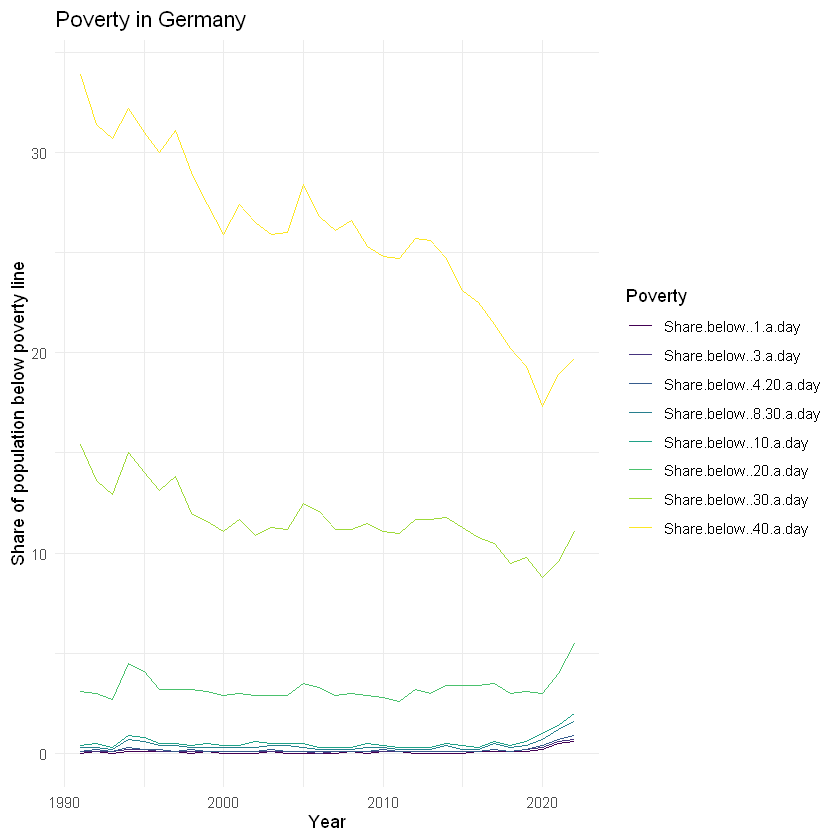

In [15]:
data_poverty %>%
    filter(Country == "Germany") %>%
    pivot_longer(cols = starts_with("Share.below"), names_to = "Poverty", values_to = "share") %>%
    mutate(Poverty = factor(Poverty, levels = lines, ordered = T)) %>%
    ggplot(aes(x = Year, y = share, color = Poverty)) +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in Germany",
         x = "Year",
         y = "Share of population below poverty line")


In [19]:
head(data_pip)
data_pip$welfare_type |> unique()


,region_name,region_code,country_name,country_code,reporting_year,reporting_level,survey_acronym,survey_coverage,survey_year,welfare_type,⋯,reporting_pop,reporting_gdp,reporting_pce,is_interpolated,distribution_type,estimation_type,spl,spr,pg,estimate_type
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
1,Sub-Saharan Africa,SSF,Angola,AGO,2000,national,HBS,national,2000.21,consumption,⋯,16310860,2172.463,NA,FALSE,micro,survey,3.950,0.3714692,9.609202,NA
2,Sub-Saharan Africa,SSF,Angola,AGO,2008,national,IBEP-MICS,national,2008.50,consumption,⋯,21996714,3559.195,1748.428,FALSE,micro,survey,3.967,0.3533580,6.838756,NA
3,Sub-Saharan Africa,SSF,Angola,AGO,2018,national,IDREA,national,2018.17,consumption,⋯,31480496,3196.790,2261.456,FALSE,micro,survey,3.240,0.4216190,10.964242,NA
4,Europe & Central Asia,ECS,Albania,ALB,1996,national,EWS,national,1996.00,consumption,⋯,3168033,1683.770,1522.872,FALSE,micro,survey,5.010,0.2039019,4.209428,NA
5,Europe & Central Asia,ECS,Albania,ALB,2002,national,LSMS,national,2002.00,consumption,⋯,3051010,2297.109,1572.295,FALSE,micro,survey,4.859,0.2244040,4.429310,NA
6,Europe & Central Asia,ECS,Albania,ALB,2005,national,LSMS,national,2005.00,consumption,⋯,3011487,2712.870,1969.242,FALSE,micro,survey,5.450,0.2099751,3.860997,NA


[1] "consumption" "income"

In [20]:
colnames(data_pip)

[1] "region_name"          "region_code"          "country_name"        
 [4] "country_code"         "reporting_year"       "reporting_level"     
 [7] "survey_acronym"       "survey_coverage"      "survey_year"         
[10] "welfare_type"         "survey_comparability" "comparable_spell"    
[13] "poverty_line"         "headcount"            "poverty_gap"         
[16] "poverty_severity"     "watts"                "mean"                
[19] "median"               "mld"                  "gini"                
[22] "polarization"         "decile1"              "decile2"             
[25] "decile3"              "decile4"              "decile5"             
[28] "decile6"              "decile7"              "decile8"             
[31] "decile9"              "decile10"             "cpi"                 
[34] "ppp"                  "reporting_pop"        "reporting_gdp"       
[37] "reporting_pce"        "is_interpolated"      "distribution_type"   
[40] "estimation_type"      "spl"                  "spr"                 
[43] "pg"                   "estimate_type"